In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

Konfiigurasi Tampilan

In [29]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 10})

Load Dataset

In [30]:
df_raw = pd.read_csv('student_data.csv')
df_clean = df_raw.copy()

In [ ]:
Pengecekan Missing Value

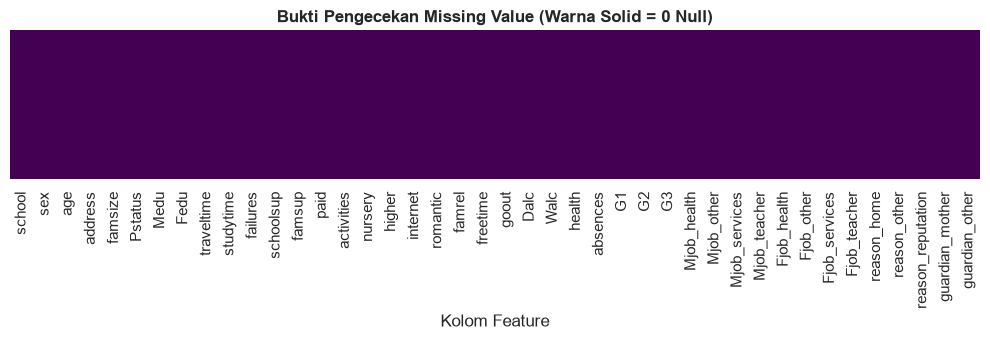

In [41]:
plt.figure(figsize=(10, 3.5))
sns.heatmap(df_clean.isnull(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Bukti Pengecekan Missing Value (Warna Solid = 0 Null)", fontsize=12, fontweight='bold')
plt.xlabel("Kolom Feature")
plt.tight_layout()
plt.show()

Deteksi Duplikasi Data

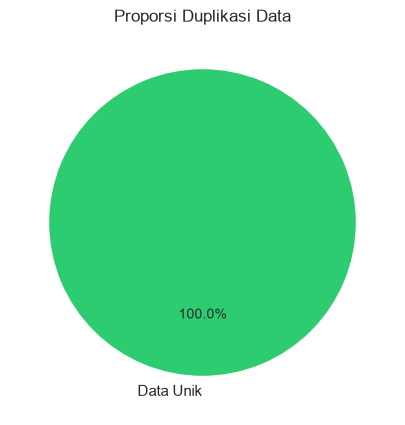

In [66]:
# Hitung dan plot pie chart dalam bentuk lingkaran
df.duplicated().value_counts().rename({False: 'Data Unik', True: 'Data Duplikat'}).plot(
    kind='pie', autopct='%1.1f%%', colors=['#2ecc71', '#e74c3c'], startangle=90, figsize=(5, 5)
)

plt.title('Proporsi Duplikasi Data')
plt.ylabel('') 
plt.show()

Deteksi Outlier pada 'absences' dengan IQR Capping

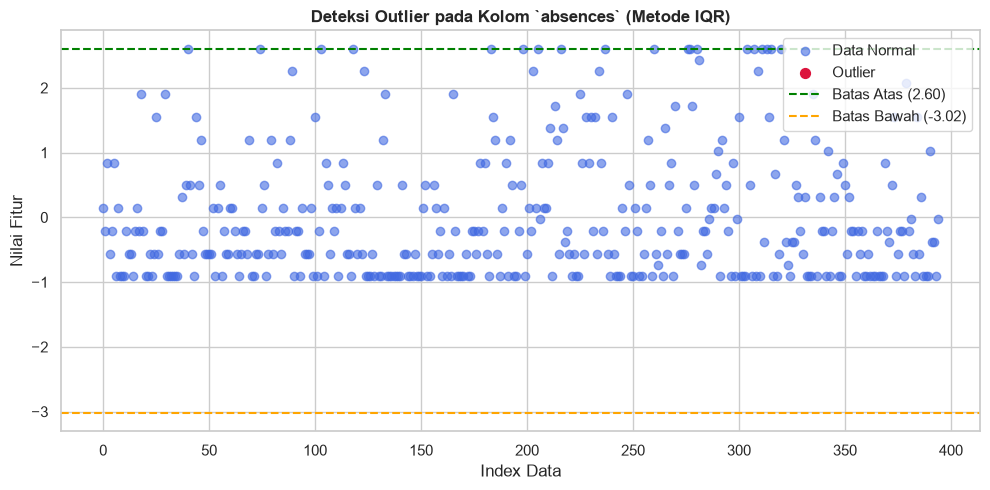

In [65]:
#Tentukan kolom target
target_col = 'absences'

#Hitung Kuartil dan Batas IQR
Q1 = df[target_col].quantile(0.25)
Q3 = df[target_col].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

#Penandaan outlier
df['is_outlier'] = (df[target_col] < lower_bound) | (df[target_col] > upper_bound)

#Visualisasi Scatter Plot
plt.figure(figsize=(10, 5))
plt.scatter(
    df[~df['is_outlier']].index, 
    df[~df['is_outlier']][target_col], 
    color='royalblue', alpha=0.6, label='Data Normal'
)
plt.scatter(
    df[df['is_outlier']].index, 
    df[df['is_outlier']][target_col], 
    color='crimson', s=50, label='Outlier'
)

# Garis ambang batas IQR
plt.axhline(upper_bound, color='green', linestyle='--', linewidth=1.5, label=f'Batas Atas ({upper_bound:.2f})')
plt.axhline(lower_bound, color='orange', linestyle='--', linewidth=1.5, label=f'Batas Bawah ({lower_bound:.2f})')

plt.title(f'Deteksi Outlier pada Kolom `{target_col}` (Metode IQR)', fontsize=12, fontweight='bold')
plt.xlabel('Index Data')
plt.ylabel('Nilai Fitur')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

Visualisasi Feature Scaling

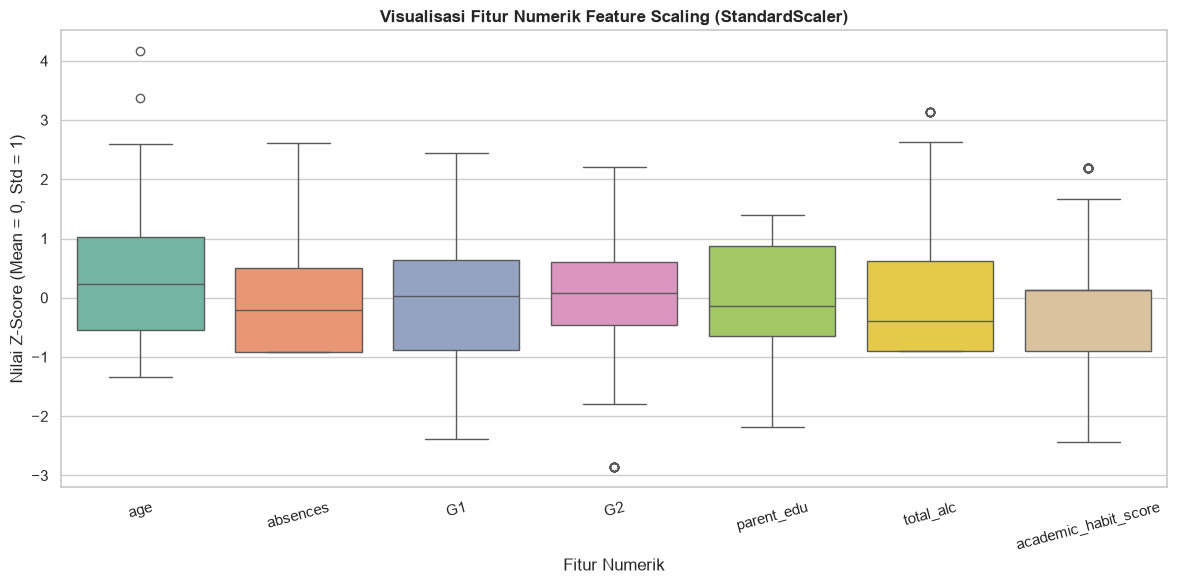

In [72]:
df_clean['parent_edu'] = (df_clean['Medu'] + df_clean['Fedu']) / 2
df_clean['total_alc'] = df_clean['Dalc'] + df_clean['Walc']
df_clean['academic_habit_score'] = df_clean['studytime'] - (df_clean['failures'] * 0.5)

# 1. Tentukan daftar fitur numerik
numerical_features = ['age', 'absences', 'G1', 'G2', 'parent_edu', 'total_alc', 'academic_habit_score']

# 2. Terapkan StandardScaler (Feature Scaling)
scaler = StandardScaler()
df_clean[numerical_features] = scaler.fit_transform(df_clean[numerical_features])

# 3. Visualisasi Boxplot (Hasil skala Z-Score)
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_clean[numerical_features], palette='Set2')

plt.title('Visualisasi Fitur Numerik Feature Scaling (StandardScaler)', fontsize=12, fontweight='bold')
plt.xlabel('Fitur Numerik')
plt.ylabel('Nilai Z-Score (Mean = 0, Std = 1)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

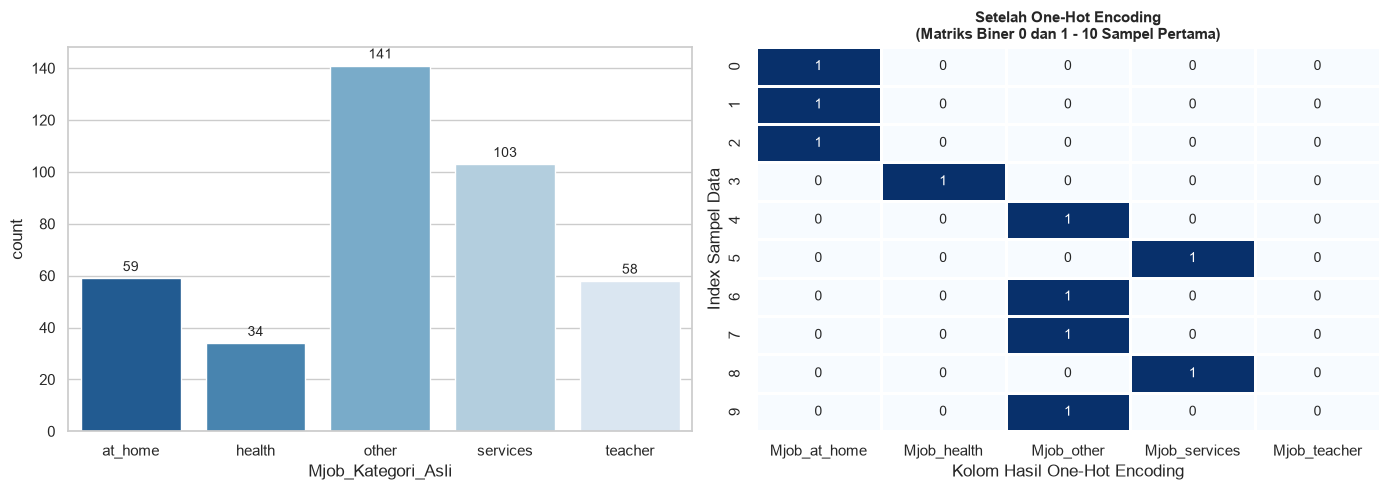

In [60]:
# Rekonstruksi kategori asli 'Mjob' dari kolom One-Hot Encoding
def get_mjob(row):
    if row.get('Mjob_health') == 1: return 'health'
    elif row.get('Mjob_other') == 1: return 'other'
    elif row.get('Mjob_services') == 1: return 'services'
    elif row.get('Mjob_teacher') == 1: return 'teacher'
    else: return 'at_home'

df['Mjob_Kategori_Asli'] = df.apply(get_mjob, axis=1)

# Lakukan One-Hot Encoding
mjob_ohe = pd.get_dummies(df['Mjob_Kategori_Asli'], prefix='Mjob', dtype=int)

# Buat layout visualisasi (1 baris, 2 kolom)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Kiri: Sebelum Encoding (Frekuensi Kategori String)
order = ['at_home', 'health', 'other', 'services', 'teacher']
sns.countplot(
    x='Mjob_Kategori_Asli', 
    data=df, 
    order=order, 
    ax=axes[0], 
    hue='Mjob_Kategori_Asli',  # Tambahkan ini
    palette='Blues_r', 
    legend=False               # Sembunyikan legenda agar rapi
)

# Menambahkan angka frekuensi di atas setiap bar
for p in axes[0].patches:
    height = p.get_height()
    if height > 0:
        axes[0].annotate(f'{int(height)}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

# Plot Kanan: Setelah Encoding (Heatmap Matriks Biner 0 dan 1)
sns.heatmap(mjob_ohe.head(10), annot=True, cbar=False, cmap='Blues', linewidths=1, ax=axes[1], fmt='d')
axes[1].set_title('Setelah One-Hot Encoding\n(Matriks Biner 0 dan 1 - 10 Sampel Pertama)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Kolom Hasil One-Hot Encoding')
axes[1].set_ylabel('Index Sampel Data')

plt.tight_layout()
plt.show()